# 02 — Naive baseline (Yussuf)

**What this notebook does:** it makes the simplest forecast we can think of, and measures how wrong it is.

**The idea in one sentence:** *"the sales of a product in a store on some day will be the same as on the same weekday three weeks earlier."*

**Why we need it:** a baseline is the number to beat. A real model (Linear, Random Forest, XGBoost ...) is only useful if its error is **lower** than this one. If a model cannot beat "copy the sales from 3 weeks ago", it has learned nothing useful.

Nothing is trained here. There is no machine learning in a naive baseline — that is the point.

## 1. Settings

These are the rules the team agreed on. They are written once here so every number below comes from them.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Project folder: works when the notebook runs from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

HORIZON = 16   # we must forecast 16 days into the future
LAG = 21       # the baseline copies the sales from 21 days ago

TRAIN_END = "2017-06-30"
VAL_START, VAL_END = "2017-07-01", "2017-07-30"
TEST_START, TEST_END = "2017-07-31", "2017-08-15"

## 2. Load the data

We only need four columns: the day, the store, the product family, and how many units were sold.

Zenab's cleaning does **not** change these four columns (her validation report proves it), so reading the raw file gives exactly the same result as reading her cleaned file.

In [2]:
df = pd.read_csv(
    ROOT / "data" / "raw" / "train.csv",
    usecols=["date", "store_nbr", "family", "sales"],
    parse_dates=["date"],
)

n_series = df[["store_nbr", "family"]].drop_duplicates().shape[0]
print(f"{len(df):,} rows, from {df['date'].min().date()} to {df['date'].max().date()}")
print(f"{df['store_nbr'].nunique()} stores x {df['family'].nunique()} families = {n_series} series")
df.head()

3,000,888 rows, from 2013-01-01 to 2017-08-15
54 stores x 33 families = 1782 series


,date,store_nbr,family,sales
0,2013-01-01,1,AUTOMOTIVE,0.0
1,2013-01-01,1,BABY CARE,0.0
2,2013-01-01,1,BEAUTY,0.0
3,2013-01-01,1,BEVERAGES,0.0
4,2013-01-01,1,BOOKS,0.0


## 3. Why 21 days, and not 7?

A **series** is one product family in one store (for example: store 1, GROCERY I). Each series is a list of daily sales.

We forecast **16 days ahead**. Imagine today is day 0 and we must predict day 16:

| look back | which day is that? | do we know it today? |
|---|---|---|
| 7 days | day 9 | **No** — it is still in the future |
| 14 days | day 2 | **No** — still in the future |
| 16 days | day 0 (today) | Yes, but it is a different weekday |
| **21 days** | day −5 | **Yes**, and it is the **same weekday** |

Sales depend a lot on the weekday (weekends sell much more). So we want to copy from the same weekday, which means going back a multiple of 7. The first multiple of 7 that is not in the future is **21**.

Using lag 7 would be **data leakage**: the model would be using information it could never have in real life. Its score would look great and be worthless.

## 4. Make the prediction

For every row we want: *the sales of the same store and the same family, exactly 21 days earlier.*

The trick: take a copy of the table, push every date 21 days forward, and join it back. A row dated 25 July becomes a row dated 15 August — so it lands next to the day it is the prediction for.

We match by **date**, not by counting rows, because the data has no row for 25 December (stores are closed). Counting rows would be off by one day after each Christmas.

In [3]:
KEYS = ["store_nbr", "family"]

past = df.copy()
past["date"] = past["date"] + pd.Timedelta(days=LAG)   # push every row 21 days forward
past = past.rename(columns={"sales": "prediction"})

df = df.merge(past, on=KEYS + ["date"], how="left")
df.tail()

,date,store_nbr,family,sales,prediction
3000883,2017-08-15,9,POULTRY,438.133,320.009
3000884,2017-08-15,9,PREPARED FOODS,154.553,51.879
3000885,2017-08-15,9,PRODUCE,2419.729,2100.046
3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,5.000
3000887,2017-08-15,9,SEAFOOD,16.000,17.378


In [4]:
# Check one case by hand: the prediction for 2017-08-15 must be the real sales of 2017-07-25
one = df[(df["store_nbr"] == 1) & (df["family"] == "GROCERY I")].set_index("date")
print("prediction for 2017-08-15:", one.loc["2017-08-15", "prediction"])
print("real sales  on 2017-07-25:", one.loc["2017-07-25", "sales"])

prediction for 2017-08-15: 2405.0
real sales  on 2017-07-25: 2405.0


## 5. Split by date

- **Train** — the past the models learn from.
- **Validation** — used to compare models and choose the best one.
- **Test** — touched once at the very end, to report the final honest score.

We split by **date** and never shuffle. With time data, shuffling would let the model see the future.

The naive baseline learns nothing, so it does not really use the train part. We still split the same way so its score is measured on **exactly the same days** as every other model.

In [5]:
train = df[df["date"] <= TRAIN_END]
val = df[(df["date"] >= VAL_START) & (df["date"] <= VAL_END)]
test = df[(df["date"] >= TEST_START) & (df["date"] <= TEST_END)]

for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:11s}{len(part):>10,} rows   {part['date'].min().date()} -> {part['date'].max().date()}   {part['date'].nunique()} days")

missing = int(val["prediction"].isna().sum() + test["prediction"].isna().sum())
print("rows without a prediction in validation + test:", missing)

train       2,918,916 rows   2013-01-01 -> 2017-06-30   1638 days
validation     53,460 rows   2017-07-01 -> 2017-07-30   30 days
test           28,512 rows   2017-07-31 -> 2017-08-15   16 days
rows without a prediction in validation + test: 0


## 6. Measure the error

Three numbers, all "lower is better":

- **MAE** (mean absolute error): on average, how many units are we off per row?
- **RMSE**: like MAE, but big mistakes are punished much more.
- **WAPE**: all the errors added up, divided by all the real sales added up. Read it as *"we are wrong by X% of total sales."* This is the main number we compare.

Why not the usual percentage error (MAPE)? It divides by the real sales of each row, and many rows have zero sales — you cannot divide by zero. WAPE divides once, by the total.

In [6]:
def score(actual, predicted):
    error = (actual - predicted).abs()
    return {
        "MAE": error.mean(),
        "RMSE": np.sqrt(((actual - predicted) ** 2).mean()),
        "WAPE_%": 100 * error.sum() / actual.sum(),
    }

scores = {
    "validation": score(val["sales"], val["prediction"]),
    "test": score(test["sales"], test["prediction"]),
}
results = pd.DataFrame(scores).T.round(2)
results.to_csv(ROOT / "reports" / "naive_baseline_metrics.csv")
results

,MAE,RMSE,WAPE_%
validation,85.54,318.98,17.50
test,92.72,335.98,19.85


## 7. Look at it

Each point is one day: all stores and all families added up. The closer the two lines, the better the forecast.

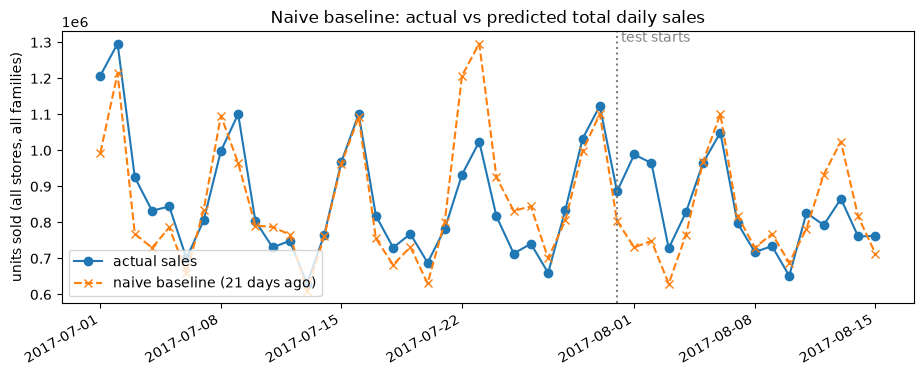

In [7]:
both = pd.concat([val, test])
daily = both.groupby("date")[["sales", "prediction"]].sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily["sales"], marker="o", label="actual sales")
ax.plot(daily.index, daily["prediction"], marker="x", linestyle="--", label="naive baseline (21 days ago)")
ax.axvline(pd.Timestamp(TEST_START), color="grey", linestyle=":")
ax.text(pd.Timestamp(TEST_START), ax.get_ylim()[1], " test starts", va="top", color="grey")
ax.set(title="Naive baseline: actual vs predicted total daily sales", ylabel="units sold (all stores, all families)")
ax.legend(loc="lower left")
fig.autofmt_xdate()
fig.savefig(ROOT / "reports" / "figures" / "naive_baseline_actual_vs_predicted.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Where is it most wrong?

The same WAPE, but for each product family separately (the 8 biggest families). This shows which products are easy to predict and which are hard.

In [8]:
both = both.assign(abs_error=(both["sales"] - both["prediction"]).abs())
by_family = both.groupby("family").agg(actual_units=("sales", "sum"), abs_error=("abs_error", "sum"))
by_family["WAPE_%"] = (100 * by_family["abs_error"] / by_family["actual_units"]).round(1)
by_family[["actual_units", "abs_error"]] = by_family[["actual_units", "abs_error"]].round(0)
by_family.sort_values("actual_units", ascending=False).head(8)

,actual_units,abs_error,WAPE_%
family,,,
GROCERY I,11584131.0,1912843.0,16.5
BEVERAGES,9013958.0,1733028.0,19.2
PRODUCE,5860986.0,675284.0,11.5
CLEANING,3274945.0,899479.0,27.5
DAIRY,2180056.0,300895.0,13.8
BREAD/BAKERY,1366287.0,203615.0,14.9
POULTRY,975583.0,161733.0,16.6
MEATS,942296.0,162063.0,17.2


## 9. Log the run in MLflow

MLflow is a logbook for experiments. Every time someone runs a model, it writes down **what was run** (the settings) and **what score it got**, so the team can compare all models in one table later.

To open the logbook, run this in a terminal from the project folder, then open the link it prints:

```
mlflow ui --backend-store-uri sqlite:///mlflow.db
```

In [9]:
import os
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"   # stops MLflow printing a hint that is not for us
import logging
import mlflow

logging.getLogger("mlflow").setLevel(logging.WARNING)    # hides MLflow's set-up messages
logging.getLogger("alembic").setLevel(logging.WARNING)

mlflow.set_tracking_uri(f"sqlite:///{ROOT / 'mlflow.db'}")
mlflow.set_experiment("stockwise-ai")

with mlflow.start_run(run_name="naive_lag21"):
    mlflow.log_params({
        "model": "naive_lag",
        "owner": "Yussuf",
        "lag_days": LAG,
        "horizon_days": HORIZON,
        "train_end": TRAIN_END,
        "validation": f"{VAL_START}..{VAL_END}",
        "test": f"{TEST_START}..{TEST_END}",
    })
    prefix = {"validation": "val", "test": "test"}   # team naming rule: val_mae, val_rmse, val_wape, ...
    for split, values in scores.items():
        for metric, value in values.items():
            mlflow.log_metric(f"{prefix[split]}_{metric.replace('_%', '').lower()}", float(value))

print("Run saved to MLflow.")

Run saved to MLflow.


## 10. The number to beat

In [10]:
print(f"Validation WAPE: {scores['validation']['WAPE_%']:.2f}%")
print(f"Test WAPE:       {scores['test']['WAPE_%']:.2f}%")
print()
print("A model is only worth keeping if its validation WAPE is LOWER than the validation number above.")

Validation WAPE: 17.50%
Test WAPE:       19.85%

A model is only worth keeping if its validation WAPE is LOWER than the validation number above.
